In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import sys
import numpy
import torch

print("Python:", sys.version.split()[0])
print("NumPy:", numpy.__version__)
print("PyTorch:", torch.__version__)

Python: 3.13.18
NumPy: 2.1.3
PyTorch: 2.11.0+cpu


In [2]:
%pip install -q --no-deps "compressai==1.2.8" "pytorch-msssim" "torch-geometric" "einops"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


In [3]:
import subprocess
import sys

check = subprocess.run(
    [
        sys.executable,
        "-c",
        """
import numpy
import torch
import compressai
from compressai.zoo import bmshj2018_factorized

print("NumPy:", numpy.__version__)
print("PyTorch:", torch.__version__)
print("CompressAI:", compressai.__version__)
print("COMPRESSAI READY")
"""
    ],
    capture_output=True,
    text=True
)

print(check.stdout)
if check.returncode != 0:
    print(check.stderr[-4000:])

NumPy: 2.1.3
PyTorch: 2.11.0+cpu
CompressAI: 1.2.8
COMPRESSAI READY



In [4]:

from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from io import BytesIO
from PIL import Image
from compressai.zoo import bmshj2018_factorized
import torch
import numpy as np
import random
import math
import json
import struct

torch.set_num_threads(4)

ROOT = Path("/kaggle/input")
OUT = Path("/kaggle/working/compressai_bitrate_pilot.json")
SAMPLE_COUNT = 12
TARGETS = [0.125, 0.25, 0.5]

def is_val_image(name):
    parts = PurePosixPath(str(name)).parts
    return any(
        parts[i:i+2] == ("val", "img")
        for i in range(len(parts)-1)
    ) and str(name).lower().endswith(".png")

# Find the validation images in the Kaggle input.
archives = sorted(ROOT.rglob("*val_test_csv*.zip"))

if archives:
    with ZipFile(archives[0]) as z:
        names = sorted(n for n in z.namelist() if is_val_image(n))
        assert len(names) >= 40, "Expected validation images in ZIP"
        chosen = random.Random(42).sample(names, 40)[:SAMPLE_COUNT]
        images = [
            np.array(
                Image.open(BytesIO(z.read(n))).convert("L"),
                dtype=np.uint8
            ) for n in chosen
        ]
else:
    names = sorted(
        p for p in ROOT.rglob("*.png")
        if is_val_image(p.as_posix())
    )
    assert len(names) >= 40, "Validation images not found"
    chosen = random.Random(42).sample(names, 40)[:SAMPLE_COUNT]
    images = []
    for p in chosen:
        with Image.open(p) as im:
            images.append(np.asarray(im.convert("L")).copy())

assert all(im.shape == (512, 512) for im in images)

# Create a small real container for the encoded streams.
def pack_streams(encoded, quality):
    shape = encoded["shape"]
    groups = encoded["strings"]
    f = BytesIO()
    f.write(b"MCP1")
    f.write(struct.pack(
        "<BHHHHB", quality, 512, 512,
        int(shape[0]), int(shape[1]), len(groups)
    ))
    for group in groups:
        f.write(struct.pack("<H", len(group)))
        for stream in group:
            f.write(struct.pack("<I", len(stream)))
            f.write(stream)
    return f.getvalue()

def unpack_streams(blob):
    f = BytesIO(blob)
    assert f.read(4) == b"MCP1"
    quality, h, w, sh, sw, n = struct.unpack(
        "<BHHHHB", f.read(10)
    )
    groups = []
    for _ in range(n):
        count = struct.unpack("<H", f.read(2))[0]
        group = []
        for _ in range(count):
            length = struct.unpack("<I", f.read(4))[0]
            group.append(f.read(length))
        groups.append(group)
    assert f.read() == b""
    return quality, (h, w), (sh, sw), groups

results = []
print("Images:", len(images))
print("Pretrained CompressAI bitrate screening\n")

for quality in range(1, 9):
    model = bmshj2018_factorized(
        quality=quality,
        metric="mse",
        pretrained=True
    ).cpu().eval()

    # Prepare entropy coder for actual bitstreams.
    model.update(force=True)

    bpps, psnrs = [], []

    with torch.no_grad():
        for original in images:
            gray = torch.from_numpy(
                original.copy()
            ).float()[None, None] / 255.0

            # Repeat grayscale to RGB for pretrained model.
            rgb = gray.repeat(1, 3, 1, 1)

            encoded = model.compress(rgb)
            blob = pack_streams(encoded, quality)

            q, dims, shape, strings = unpack_streams(blob)
            assert q == quality and dims == (512, 512)

            reconstructed = model.decompress(
                strings, shape
            )["x_hat"]

            # Common provisional grayscale output policy.
            gray_hat = reconstructed.clamp(0, 1).mean(
                dim=1, keepdim=True
            )

            # Quantize back to 8-bit grayscale, as in JPEG2000.
            decoded_u8 = (
                gray_hat.mul(255).round()
                .to(torch.uint8)
                .squeeze().numpy()
            )

            a = original.astype(np.float64)
            b = decoded_u8.astype(np.float64)
            mse = float(np.mean((a - b) ** 2))

            psnr = float("inf") if mse == 0 else (
                10 * math.log10(255.0**2 / mse)
            )

            bpps.append(len(blob) * 8 / (512 * 512))
            psnrs.append(psnr)

    record = {
        "quality": quality,
        "mean_bpp": float(np.mean(bpps)),
        "mean_psnr_db": float(np.mean(psnrs)),
        "min_bpp": float(np.min(bpps)),
        "max_bpp": float(np.max(bpps))
    }
    results.append(record)

    print(
        f"Quality {quality}: "
        f"Actual bpp {record['mean_bpp']:.4f} | "
        f"PSNR {record['mean_psnr_db']:.2f} dB"
    )
    del model

print("\nCLOSEST QUALITY LEVELS")
for target in TARGETS:
    best = min(
        results,
        key=lambda r: abs(r["mean_bpp"] - target)
    )
    diff = 100 * (best["mean_bpp"] / target - 1)
    print(
        f"Target {target:.3f}: "
        f"quality {best['quality']} | "
        f"actual {best['mean_bpp']:.4f} bpp | "
        f"difference {diff:+.1f}%"
    )

OUT.write_text(json.dumps({
    "purpose": "Pretrained CompressAI feasibility pilot",
    "architecture": "bmshj2018_factorized",
    "samples": len(images),
    "seed": 42,
    "grayscale_policy": "repeat input to RGB; mean decoded RGB; round to 8-bit",
    "rate_policy": "actual serialized bitstream including framing metadata",
    "results": results,
    "training_performed": False
}, indent=2))

print("\nSaved:", OUT)

Images: 12
Pretrained CompressAI bitrate screening

Downloading: "https://compressai.s3.amazonaws.com/models/v1/bmshj2018-factorized-prior-1-446d5c7f.pth.tar" to /root/.cache/torch/hub/checkpoints/bmshj2018-factorized-prior-1-446d5c7f.pth.tar


100%|██████████| 11.5M/11.5M [00:02<00:00, 5.24MB/s]


Quality 1: Actual bpp 0.0749 | PSNR 32.60 dB
Downloading: "https://compressai.s3.amazonaws.com/models/v1/bmshj2018-factorized-prior-2-87279a02.pth.tar" to /root/.cache/torch/hub/checkpoints/bmshj2018-factorized-prior-2-87279a02.pth.tar


100%|██████████| 11.5M/11.5M [00:00<00:00, 17.5MB/s]


Quality 2: Actual bpp 0.1136 | PSNR 33.65 dB
Downloading: "https://compressai.s3.amazonaws.com/models/v1/bmshj2018-factorized-prior-3-5c6f152b.pth.tar" to /root/.cache/torch/hub/checkpoints/bmshj2018-factorized-prior-3-5c6f152b.pth.tar


100%|██████████| 11.6M/11.6M [00:00<00:00, 16.3MB/s]


... (7 outputs left out)

100%|██████████| 27.5M/27.5M [00:01<00:00, 25.5MB/s]


Quality 7: Actual bpp 0.8093 | PSNR 41.30 dB
Downloading: "https://compressai.s3.amazonaws.com/models/v1/bmshj2018-factorized-prior-8-5232faa3.pth.tar" to /root/.cache/torch/hub/checkpoints/bmshj2018-factorized-prior-8-5232faa3.pth.tar


100%|██████████| 27.9M/27.9M [00:01<00:00, 22.3MB/s]


Quality 8: Actual bpp 1.1356 | PSNR 43.41 dB

CLOSEST QUALITY LEVELS
Target 0.125: quality 2 | actual 0.1136 bpp | difference -9.2%
Target 0.250: quality 4 | actual 0.2594 bpp | difference +3.8%
Target 0.500: quality 6 | actual 0.5613 bpp | difference +12.3%

Saved: /kaggle/working/compressai_bitrate_pilot.json


In [5]:
import json
from pathlib import Path

working = Path("/kaggle/working")

compressai = json.loads(
    (working / "compressai_bitrate_pilot.json").read_text()
)

report = {
    "experiment": "Mars codec bitrate feasibility",
    "status": "preliminary, not final codec comparison",
    "dataset": "AI4Mars prepared 512x512 grayscale",
    "split": "Curiosity validation",
    "target_bpp": [0.125, 0.25, 0.5],
    "jpeg2000": {
        "sample_count": 40,
        "results": [
            {"target": 0.125, "actual_bpp": 0.1229, "psnr_db": 33.48},
            {"target": 0.250, "actual_bpp": 0.2482, "psnr_db": 35.82},
            {"target": 0.500, "actual_bpp": 0.4968, "psnr_db": 38.72}
        ]
    },
    "compressai": compressai,
    "conclusion": (
        "Both methods demonstrated operation in the proposed "
        "low-bitrate range. Exact learned-codec rate matching "
        "remains to be calibrated."
    ),
    "warning": (
        "JPEG2000 used 40 images and CompressAI used 12. "
        "Do not use these PSNR results to declare a winner."
    )
}

output = working / "codec_feasibility_summary.json"
output.write_text(json.dumps(report, indent=2))

print("Saved:", output)
print("Both experiments recorded successfully.")

Saved: /kaggle/working/codec_feasibility_summary.json
Both experiments recorded successfully.


In [6]:
import json
from pathlib import Path

policy = {
    "status": "PROPOSED - awaiting teammate agreement",
    "source_format": "512x512 8-bit grayscale PNG",
    "source_channels": 1,
    "input_range": [0, 1],
    "jpeg2000_input": "Single-channel grayscale",
    "compressai_rgb_input": "Repeat grayscale channel 3 times",
    "compressai_reconstruction": (
        "Clamp decoded RGB to [0,1], "
        "then take arithmetic mean across three channels"
    ),
    "final_evaluation": (
        "Round reconstructed grayscale to 8-bit, "
        "then apply the existing frozen SegFormer input pipeline"
    ),
    "reconstruction_metrics": [
        "PSNR", "MS-SSIM"
    ],
    "task_metrics": [
        "mIoU4", "mIoU3", "per-class IoU"
    ],
    "bitrate_denominator": "512*512 source pixels",
    "important": (
        "No extra RGB-channel factor in bitrate. "
        "Measure actual encoded bitstream bytes."
    )
}

path = Path("/kaggle/working/grayscale_policy_PROPOSED.json")
path.write_text(json.dumps(policy, indent=2))
print("Saved:", path)

Saved: /kaggle/working/grayscale_policy_PROPOSED.json


In [3]:
import os, sys, glob, json, hashlib, zipfile
from pathlib import Path

cands = glob.glob("/kaggle/input/**/dataset_v3_512_val_test_csv/dataset_v3_512", recursive=True)
assert cands, "Attach the dataset mars-terrain-v3-512 (Add Input)"
VT = Path(cands[0]); print("data:", VT)
assert (VT / "val.csv").is_file() and (VT / "val").is_dir()

zs = glob.glob("/kaggle/input/**/mars_segformer_trained_model.zip", recursive=True)
assert zs, "Upload mars_segformer_trained_model.zip as a Kaggle dataset and attach it"
PK = Path("/kaggle/working/model_pkg"); PK.mkdir(exist_ok=True)
with zipfile.ZipFile(zs[0]) as z: z.extractall(PK)

ckpt = PK / "checkpoints/baseline/frozen_best_epoch16.pt"
h = hashlib.sha256(ckpt.read_bytes()).hexdigest()
print("sha256:", h)
assert h == "afb9b155e07c617ab69cfa29455beda9318605b0afcec81e07f558a48bcbbda6", "hash mismatch: STOP"
print("HASH OK")

data: /kaggle/input/datasets/hudafatimah/mars-terrain-v3-512/dataset_v3_512_val_test_csv/dataset_v3_512


AssertionError: Upload mars_segformer_trained_model.zip as a Kaggle dataset and attach it

In [4]:
import glob, hashlib, zipfile
from pathlib import Path

# data (this part already worked for you)
cands = glob.glob("/kaggle/input/**/dataset_v3_512_val_test_csv/dataset_v3_512", recursive=True)
assert cands, "Attach the dataset mars-terrain-v3-512 (Add Input)"
VT = Path(cands[0]); print("data:", VT)
assert (VT / "val.csv").is_file() and (VT / "val").is_dir()

# model: Kaggle auto-unzips uploads, so look for the extracted checkpoint first
ck = glob.glob("/kaggle/input/**/frozen_best_epoch16.pt", recursive=True)
if ck:
    ckpt = Path(ck[0]); PK = ckpt.parents[2]
else:
    zs = glob.glob("/kaggle/input/**/mars_segformer_trained_model.zip", recursive=True)
    assert zs, "Model files not found: check that mars-segformer-model is attached under Input"
    PK = Path("/kaggle/working/model_pkg"); PK.mkdir(exist_ok=True)
    with zipfile.ZipFile(zs[0]) as z: z.extractall(PK)
    ckpt = PK / "checkpoints/baseline/frozen_best_epoch16.pt"

print("model package root:", PK)
assert (PK / "code/mars_common.py").is_file(), "mars_common.py not found in the model package"
h = hashlib.sha256(ckpt.read_bytes()).hexdigest()
print("sha256:", h)
assert h == "afb9b155e07c617ab69cfa29455beda9318605b0afcec81e07f558a48bcbbda6", "hash mismatch: STOP"
print("HASH OK")

data: /kaggle/input/datasets/hudafatimah/mars-terrain-v3-512/dataset_v3_512_val_test_csv/dataset_v3_512
model package root: /kaggle/input/datasets/hudafatimah/mars-terrain-v3-512/backup_baseline_final_evaluated
sha256: afb9b155e07c617ab69cfa29455beda9318605b0afcec81e07f558a48bcbbda6
HASH OK


In [6]:
import os, sys, json, shutil, numpy as np, pandas as pd, torch
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image
from torch.utils.data import DataLoader

os.environ["MARS_DATA"] = str(VT)            # must be set before importing mars_common
sys.path.insert(0, str(PK / "code"))
import mars_common as mc
assert Path(mc.DATA) == VT
dev = mc.DEV; print("device:", dev)

# frozen model (architecture only; all weights come from the checkpoint)
model = mc.SegWrap(pretrained=None).to(dev)
state = torch.load(ckpt, map_location="cpu", weights_only=False)
assert int(state["epoch"]) == 16 and int(state["iteration"]) == 19600
model.load_state_dict(state["model"], strict=True); model.eval()

# check: must reproduce the recorded validation score
ds = mc.MarsSeg("val")
r = mc.evaluate(model, DataLoader(ds, batch_size=16, shuffle=False, num_workers=2))
print(f"VALIDATION check  mIoU4={r['miou4']:.6f} (recorded 0.838503) | mIoU3={r['miou3']:.6f} (recorded 0.935317)")
assert abs(r["miou4"] - 0.838503) < 5e-4, "STOP: does not reproduce the frozen validation score"

# choose images from ground truth only (never by model performance)
rows = []
for i in range(len(ds)):
    m = np.array(Image.open(os.path.join(mc.DATA, ds.d.iloc[i].mask_512)))
    lab = int((m != 255).sum())
    rows.append((i, lab / m.size, (m == 3).sum() / max(lab, 1)))
st = pd.DataFrame(rows, columns=["i", "labeled", "bigrock"])
rng = np.random.RandomState(42)
pool = st[st.labeled >= 0.5]
rand8 = rng.choice(pool.i.values, 8, replace=False)
bpool = pool[(pool.bigrock >= 0.01) & (~pool.i.isin(rand8))]
big4 = rng.choice(bpool.i.values, 4, replace=False)
sel = [int(i) for i in rand8] + [int(i) for i in big4]
kinds = ["random"] * 8 + ["big-rock"] * 4

PAL = np.array([[176,141,87],[214,39,40],[240,215,50],[46,92,230]], np.uint8)
NAMES = ["Soil", "Bedrock", "Sand", "Big rock"]
def colour(m):
    o = np.zeros(m.shape + (3,), np.uint8)
    for k in range(4): o[m == k] = PAL[k]
    return o
def overlay(g, m, a=0.55):
    g3 = np.repeat(g[..., None], 3, 2).astype(np.float32)
    return np.where((m != 255)[..., None], (1 - a) * g3 + a * colour(m), g3).astype(np.uint8)
def errmap(gt, pr):
    o = np.zeros(gt.shape + (3,), np.uint8); lab = gt != 255
    o[lab & (gt == pr)] = (200, 200, 200); o[lab & (gt != pr)] = (255, 0, 255)
    return o

OUT = Path("/kaggle/working/prediction_panels"); shutil.rmtree(OUT, ignore_errors=True); OUT.mkdir()
recs = []
for n, (i, kind) in enumerate(zip(sel, kinds), 1):
    x, y = ds[i]
    with torch.no_grad(), torch.autocast(dev, dtype=mc.AMP_DT, enabled=mc.USE_AMP):
        lg = model(x.unsqueeze(0).to(dev))
    pr = lg.float().argmax(1)[0].cpu().numpy().astype(np.uint8)
    gt = y.numpy().astype(np.uint8)
    g = (x[0].numpy() * 255).round().astype(np.uint8)
    lab = gt != 255
    rec = dict(n=n, kind=kind, image_id=Path(ds.d.iloc[i].img_512).stem, val_index=i,
               labeled_frac=float(lab.mean()), pixel_acc=float((pr[lab] == gt[lab]).mean()))
    for k, nm in enumerate(NAMES):
        tp = int(((gt == k) & (pr == k) & lab).sum())
        gk = int(((gt == k) & lab).sum()); pk = int(((pr == k) & lab).sum())
        rec[f"gt_share_{nm}"] = gk / max(int(lab.sum()), 1)
        rec[f"iou_{nm}"] = tp / (gk + pk - tp) if (gk + pk - tp) > 0 else float("nan")
    recs.append(rec)
    fig, ax = plt.subplots(1, 4, figsize=(16, 4.4))
    for a_, im_, t in zip(ax, [g, overlay(g, gt), overlay(g, pr), errmap(gt, pr)],
                          ["Image", "Ground truth", "Prediction", "Errors (magenta = wrong)"]):
        a_.imshow(im_, cmap="gray" if im_.ndim == 2 else None, vmin=0, vmax=255, interpolation="nearest")
        a_.set_title(t); a_.axis("off")
    fig.suptitle(f"{n:02d} | {rec['image_id']} | {kind} | pixel acc {rec['pixel_acc']:.3f}", fontsize=10)
    plt.tight_layout(); fig.savefig(OUT / f"panel_{n:02d}.png", dpi=130); plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 0.6)); ax.axis("off")
ax.legend(handles=[Patch(color=PAL[k] / 255, label=f"{k} {NAMES[k]}") for k in range(4)] +
          [Patch(color="black", label="255 ignored")], ncol=5, loc="center", frameon=False)
fig.savefig(OUT / "legend.png", dpi=130, bbox_inches="tight"); plt.close(fig)

pd.DataFrame(recs).to_csv(OUT / "prediction_examples.csv", index=False)
json.dump(dict(split="val", checkpoint_sha256=h, epoch=16, iteration=19600,
               rule="8 random + 4 big-rock (>=1% of labeled pixels) validation images with >=50% labeled pixels; "
                    "RandomState(42); chosen from ground truth only, never by model performance",
               val_indices=sel, full_val_miou4=r["miou4"], full_val_miou3=r["miou3"]),
          open(OUT / "panel_manifest.json", "w"), indent=2)
shutil.make_archive("/kaggle/working/prediction_panels", "zip", OUT)
print("DONE:", len(recs), "panels | zip MB:", round(os.path.getsize("/kaggle/working/prediction_panels.zip") / 1e6, 1))
print(pd.DataFrame(recs)[["n", "kind", "image_id", "pixel_acc"]].round(3).to_string(index=False))

device: cuda
VALIDATION check  mIoU4=0.838503 (recorded 0.838503) | mIoU3=0.935317 (recorded 0.935317)
DONE: 12 panels | zip MB: 7.5
 n     kind                             image_id  pixel_acc
 1   random NLB_549040132EDR_F0631840NCAM00354M1      0.989
 2   random NLB_624402166EDR_F0770006NCAM00289M1      0.449
 3   random NLB_495061043EDR_F0492626NCAM00268M1      0.991
 4   random NLB_540510899EDR_F0610648NCAM00270M1      0.991
 5   random NLB_482545422EDR_F0461162NCAM00354M1      1.000
 6   random NLB_567238122EDR_F0671762NCAM07753M1      0.991
 7   random NLB_624317263EDR_F0770000NCAM00354M1      0.895
 8   random NLB_444809000EDR_F0260292NCAM00257M1      1.000
 9 big-rock NLB_548858669EDR_F0631636NCAM00277M1      0.968
10 big-rock NLB_548857917EDR_F0631606NCAM00385M1      0.974
11 big-rock NLB_483340361EDR_F0470522NCAM00253M1      0.921
12 big-rock NLB_484059426EDR_F0470598NCAM00223M1      0.941


In [1]:
%pip install -q --no-deps pytorch-msssim
import glob
from pathlib import Path
VT = Path(glob.glob("/kaggle/input/**/dataset_v3_512_val_test_csv/dataset_v3_512", recursive=True)[0])
print("data:", VT)

Note: you may need to restart the kernel to use updated packages.
data: /kaggle/input/datasets/hudafatimah/mars-terrain-v3-512/dataset_v3_512_val_test_csv/dataset_v3_512


encoder: pillow13.0.0-openjpeg2.5.4-irreversible97-rates-rawJ2K
validation images: 1192 | id-list sha256: 6168c46845d61bb6
  target 0.125: ratio 62.988 -> full-val mean 0.1249 bpp (-0.06%)
  target 0.25: ratio 31.710 -> full-val mean 0.2499 bpp (-0.03%)
  target 0.5: ratio 15.909 -> full-val mean 0.5001 bpp (+0.02%)

SUMMARY (validation, all images)
 target_bpp  target_bytes  n_images  ratio_param  mean_actual_bpp  deviation_pct  bpp_std  bpp_min  bpp_max  pct_images_within_5pct  mean_bytes  mean_jp2_extra_bytes  mean_psnr_db  mean_ms_ssim  decode_failures
      0.125        4096.0      1192      62.9878           0.1249        -0.0589   0.0024   0.1138   0.1275                  97.651   4093.5856                4.5747       33.1070        0.9356                0
      0.250        8192.0      1192      31.7096           0.2499        -0.0299   0.0027   0.2383   0.2528                 100.000   8189.5512                2.6342       35.4959        0.9675                0
      0.500    

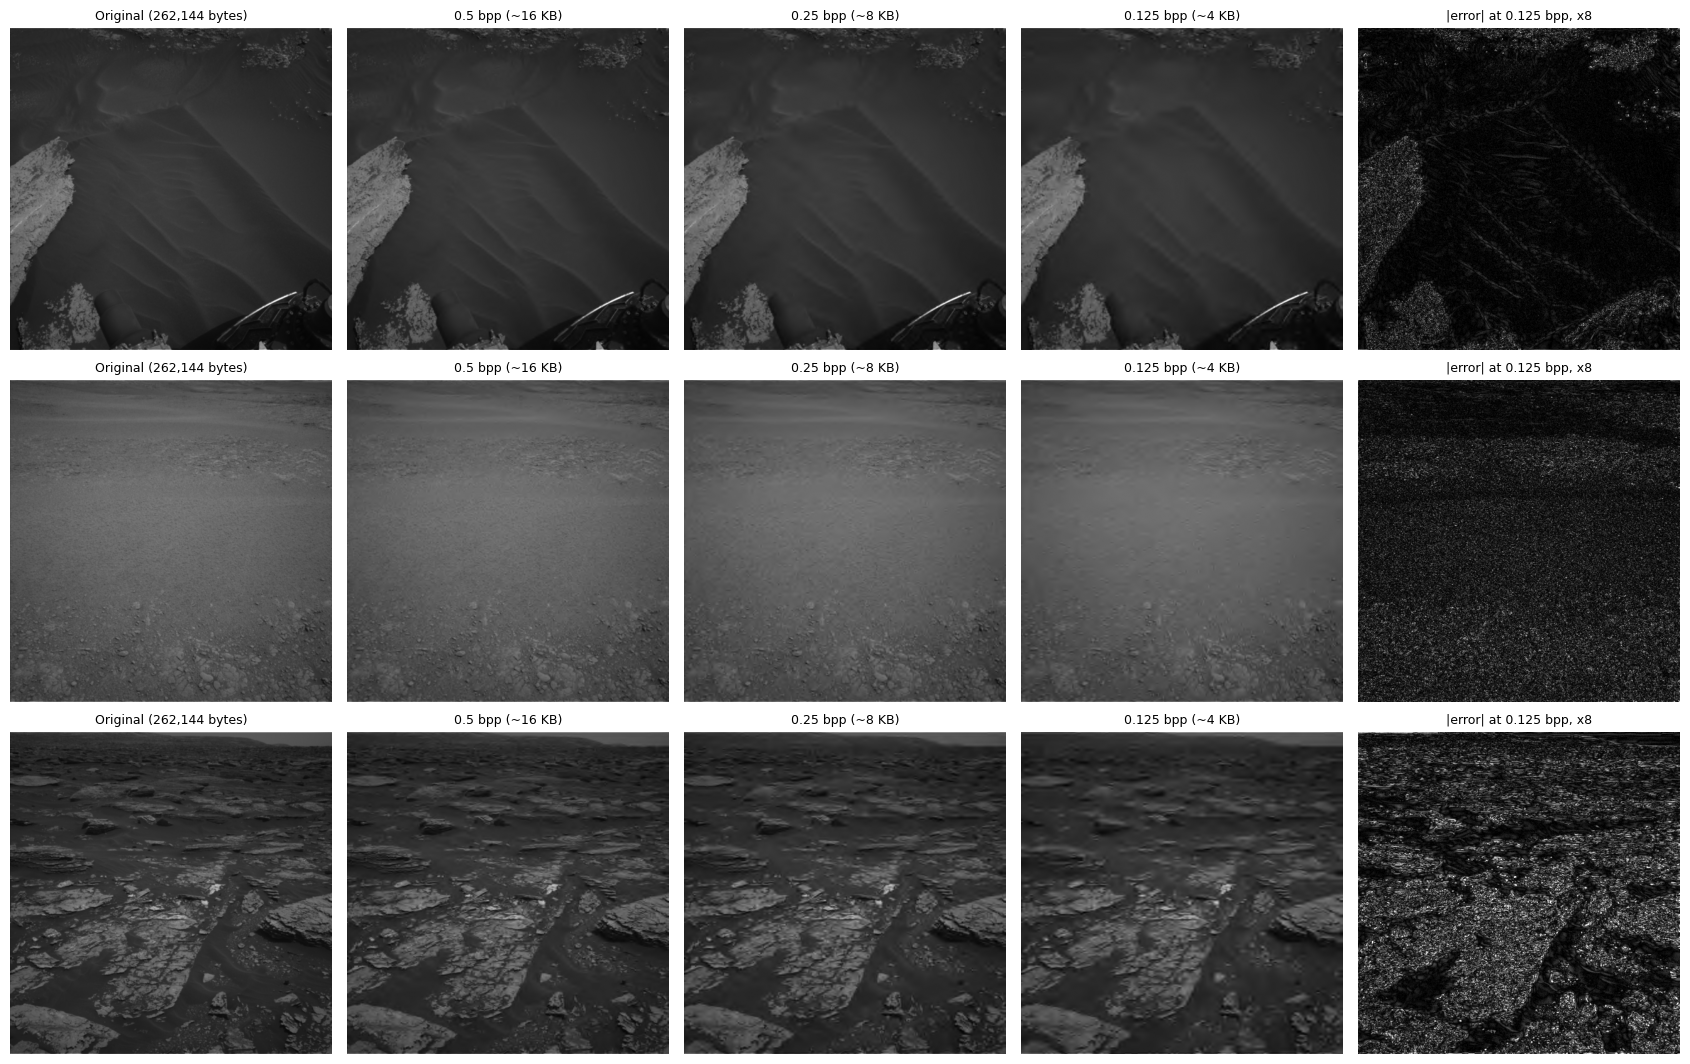


Saved: /kaggle/working/jpeg2000_calibration.zip (per_image.csv, summary.json, what_compression_does.png)


In [2]:
import io, json, hashlib, time, numpy as np, pandas as pd, PIL
from pathlib import Path
from PIL import Image, features
import matplotlib.pyplot as plt

EXPECT  = 1192                      # size of the frozen validation split
TARGETS = [0.125, 0.25, 0.5]        # proposed operating points (bits per pixel)
BAND    = 0.01                      # calibrate JPEG2000 to within +/-1% (learned codecs get +/-5%)
N       = 512 * 512
OUTDIR  = Path("/kaggle/working/jpeg2000_calibration"); OUTDIR.mkdir(exist_ok=True)

assert features.check("jpg_2000"), "This Pillow build has no JPEG2000 support"
OPJ = features.version("jpg_2000")
CODEC_ID = f"pillow{PIL.__version__}-openjpeg{OPJ}-irreversible97-rates-rawJ2K"
print("encoder:", CODEC_ID)

# ---- fixed, ordered validation list (the same order the frozen evaluator uses) ----
val = pd.read_csv(VT / "val.csv")
assert "img_512" in val.columns, f"unexpected columns: {list(val.columns)}"
paths = [VT / p for p in val["img_512"]]
assert len(paths) == EXPECT, f"expected {EXPECT} validation images, found {len(paths)}"
assert all(p.is_file() for p in paths), "some validation images are missing"
ids  = [p.stem for p in paths]
imgs = [np.array(Image.open(p).convert("L")) for p in paths]
assert all(a.shape == (512, 512) and a.dtype == np.uint8 for a in imgs)
ids_sha = hashlib.sha256("\n".join(ids).encode()).hexdigest()
print("validation images:", len(imgs), "| id-list sha256:", ids_sha[:16])

def j2k(a, ratio, jp2=False):
    """JPEG2000 encode. ratio = compression ratio vs 8 bits/pixel. jp2=False -> raw J2K codestream."""
    b = io.BytesIO()
    Image.fromarray(a, "L").save(b, "JPEG2000", quality_mode="rates", quality_layers=[float(ratio)],
                                 irreversible=True, no_jp2=not jp2)
    return b.getvalue()

def mean_bpp(ratio, idx):
    return float(np.mean([len(j2k(imgs[i], ratio)) * 8 / N for i in idx]))

# ---- 1) calibrate the ratio parameter so the MEAN validation bpp hits each target ----
cal, search_idx = {}, list(range(0, len(imgs), 3))
for t in TARGETS:
    ratio = 8.0 / t
    for it in range(12):                                   # quick search on every 3rd image
        m = mean_bpp(ratio, search_idx)
        if abs(m / t - 1) <= BAND / 2: break
        ratio *= m / t
    for it in range(4):                                    # verify / refine on the full validation list
        m = mean_bpp(ratio, range(len(imgs)))
        print(f"  target {t}: ratio {ratio:.3f} -> full-val mean {m:.4f} bpp ({100*(m/t-1):+.2f}%)")
        if abs(m / t - 1) <= BAND: break
        ratio *= m / t
    cal[t] = ratio

# ---- 2) measure everything per image: bytes, bpp, decode check, PSNR, MS-SSIM ----
try:
    import torch
    from pytorch_msssim import ms_ssim
    def msssim(a, d):
        x = torch.from_numpy(a.astype(np.float32))[None, None]; y = torch.from_numpy(d.astype(np.float32))[None, None]
        return float(ms_ssim(x, y, data_range=255, size_average=True))
except Exception as e:
    print("MS-SSIM not available (run the pip cell first):", repr(e)[:120]); msssim = None

rows = []
for t in TARGETS:
    for k, a in enumerate(imgs):
        raw, wrapped = j2k(a, cal[t], False), j2k(a, cal[t], True)
        try:
            d = np.array(Image.open(io.BytesIO(raw)).convert("L")); ok = d.shape == a.shape
        except Exception:
            d, ok = None, False
        psnr = ssim = float("nan")
        if ok:
            mse = float(np.mean((a.astype(np.float64) - d.astype(np.float64)) ** 2))
            psnr = float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)
            if msssim: ssim = msssim(a, d)
        rows.append(dict(method="jpeg2000", codec_id=CODEC_ID, checkpoint_sha256="n/a (conventional codec)",
                         split="val", image_id=ids[k], target_bpp=t, ratio_param=cal[t],
                         actual_bpp=len(raw) * 8 / N, encoded_bytes=len(raw),
                         jp2_wrapped_bytes=len(wrapped), psnr_db=psnr, ms_ssim=ssim,
                         decoded_ok=ok, eval_protocol_version="v1.0-draft"))
df = pd.DataFrame(rows); df.to_csv(OUTDIR / "per_image.csv", index=False)

# ---- 3) summary ----
summ = []
for t, g in df.groupby("target_bpp"):
    g = g[g.decoded_ok]
    summ.append(dict(target_bpp=t, target_bytes=t * N / 8, n_images=len(g), ratio_param=round(float(g.ratio_param.iloc[0]), 4),
        mean_actual_bpp=g.actual_bpp.mean(), deviation_pct=100 * (g.actual_bpp.mean() / t - 1),
        bpp_std=g.actual_bpp.std(), bpp_min=g.actual_bpp.min(), bpp_max=g.actual_bpp.max(),
        pct_images_within_5pct=100 * float((abs(g.actual_bpp / t - 1) <= 0.05).mean()),
        mean_bytes=g.encoded_bytes.mean(), mean_jp2_extra_bytes=(g.jp2_wrapped_bytes - g.encoded_bytes).mean(),
        mean_psnr_db=g.psnr_db.mean(), mean_ms_ssim=g.ms_ssim.mean(),
        decode_failures=int((~df[df.target_bpp == t].decoded_ok).sum())))
S = pd.DataFrame(summ)
json.dump(dict(codec_id=CODEC_ID, pillow=PIL.__version__, openjpeg=OPJ, wavelet="irreversible 9/7",
               rate_mode="per-image rate control (quality_mode=rates, 1 layer)", bytes_counted="raw J2K codestream",
               val_ids_sha256=ids_sha, n_val=len(imgs), band=BAND, summary=summ),
          open(OUTDIR / "summary.json", "w"), indent=2, default=float)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print("\nSUMMARY (validation, all images)"); print(S.round(4).to_string(index=False))

# ---- 4) what compression actually does: original vs reconstructions ----
show = [i for i in (868, 1168, 846) if i < len(imgs)] or [0, 1, 2]
fig, ax = plt.subplots(len(show), 5, figsize=(17, 3.6 * len(show)))
ax = np.atleast_2d(ax)
for r_, i in enumerate(show):
    a = imgs[i]
    outs = [np.array(Image.open(io.BytesIO(j2k(a, cal[t]))).convert("L")) for t in (0.5, 0.25, 0.125)]
    diff = np.clip(np.abs(outs[2].astype(int) - a.astype(int)) * 8, 0, 255).astype(np.uint8)
    for c_, (im_, ttl) in enumerate(zip([a, *outs, diff],
            ["Original (262,144 bytes)", "0.5 bpp (~16 KB)", "0.25 bpp (~8 KB)", "0.125 bpp (~4 KB)", "|error| at 0.125 bpp, x8"])):
        ax[r_, c_].imshow(im_, cmap="gray", vmin=0, vmax=255); ax[r_, c_].set_title(ttl, fontsize=9); ax[r_, c_].axis("off")
plt.tight_layout(); fig.savefig(OUTDIR / "what_compression_does.png", dpi=110); plt.show()

import shutil; shutil.make_archive("/kaggle/working/jpeg2000_calibration", "zip", OUTDIR)
print("\nSaved: /kaggle/working/jpeg2000_calibration.zip (per_image.csv, summary.json, what_compression_does.png)")